<table border=0 width="100%"><tr><td><p align="left"><font size=5><B>数据分析与可视化</B></font></p></td><td><font size=3><B>结构化数据(郑海超)</B></font></td></tr></table>

# 教学内容
- How to build a career in AI
- 初步认识并应用pandas
- 使用tushare获取股票行情数据
- 应用concurrent.futures做并发操作（选学）

## 反思问题
- 我害怕上数据分析课程吗？
- 我害怕考试吗？
- 我害怕社交吗？
- 我害怕找不到理想工作吗？
- 我害怕达不到家人的期待吗？

# 克服焦虑：不刻意反思焦虑，尝试用理想指导行动

# How to build a career in AI

## Three Steps to Career Growth

[How-to-Build-a-Career-in-AI](https://home-wordpress.deeplearning.ai/wp-content/uploads/2022/10/eBook-How-to-Build-a-Career-in-AI.pdf)

- chapter 1: Three Steps to Career Growth

## Learning Technical Skills for a Promising AI Career

[How-to-Build-a-Career-in-AI](https://home-wordpress.deeplearning.ai/wp-content/uploads/2022/10/eBook-How-to-Build-a-Career-in-AI.pdf)

- chapter 2: Learning Technical Skills for a Promising AI Career

How can you maintain a steady pace of learning for years? If you can cultivate the habit of 
learning a little bit every week, you can make significant progress with what feels like less effort.

# 初步认识并应用pandas

[pandas] (https://pandas.pydata.org/docs/user_guide/index.html)

## Series

In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt

In [2]:
np.random.randn??

Signature: np.random.randn(*args)
Docstring:
randn(d0, d1, ..., dn)

Return a sample (or samples) from the "standard normal" distribution.

.. note::
    This is a convenience function for users porting code from Matlab,
    and wraps `standard_normal`. That function takes a
    tuple to specify the size of the output, which is consistent with
    other NumPy functions like `numpy.zeros` and `numpy.ones`.

.. note::
    New code should use the
    `~numpy.random.Generator.standard_normal`
    method of a `~numpy.random.Generator` instance instead;
    please see the :ref:`random-quick-start`.

If positive int_like arguments are provided, `randn` generates an array
of shape ``(d0, d1, ..., dn)``, filled
with random floats sampled from a univariate "normal" (Gaussian)
distribution of mean 0 and variance 1. A single float randomly sampled
from the distribution is returned if no argument is provided.

Parameters
----------
d0, d1, ..., dn : int, optional
    The dimensions of the returned 

## 生成1000个随机数，围绕3000上下波动

### 生成1000个标准正态分布的随机数

In [8]:
data =  4000 + np.random.randn(1000)

In [4]:
data

array([4000.24680243, 3999.09414781, 3999.52665707, ..., 4000.68107096,
       4001.71221899, 3998.47716878], shape=(4000,))

In [ ]:
plt.hist??

### 直方图展示data

(array([ 1.,  1.,  0.,  4., 10.,  8., 28., 28., 35., 53., 46., 68., 78.,
        73., 87., 83., 68., 82., 53., 60., 37., 29., 24., 15.,  7., 12.,
         6.,  2.,  1.,  1.]),
 array([3996.79554982, 3997.01594162, 3997.23633342, 3997.45672522,
        3997.67711703, 3997.89750883, 3998.11790063, 3998.33829243,
        3998.55868423, 3998.77907603, 3998.99946784, 3999.21985964,
        3999.44025144, 3999.66064324, 3999.88103504, 4000.10142684,
        4000.32181864, 4000.54221045, 4000.76260225, 4000.98299405,
        4001.20338585, 4001.42377765, 4001.64416945, 4001.86456126,
        4002.08495306, 4002.30534486, 4002.52573666, 4002.74612846,
        4002.96652026, 4003.18691206, 4003.40730387]),
 <BarContainer object of 30 artists>)

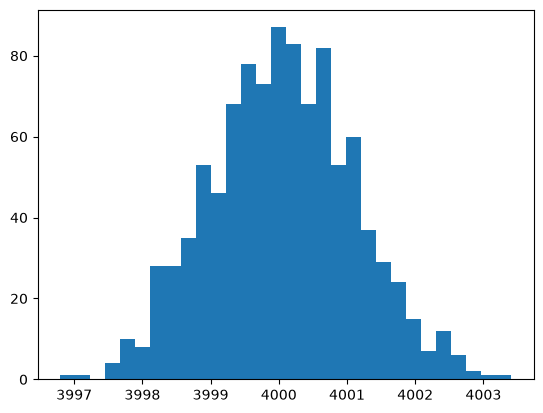

In [9]:
plt.hist(data, bins = 30)

### 用上述data生成带有索引的Series对象

In [ ]:
pd.Series??

In [10]:
### 用上述data生成带有索引的Series对象
s = pd.Series(data)

<Axes: title={'center': 'Random Numbers Around 4000'}>

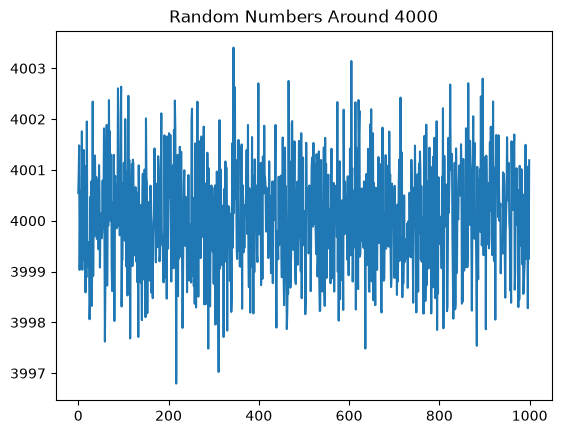

In [12]:
# plot s with a title
s.plot(title="Random Numbers Around 4000")

### 生成一个随机游走的数据
随机游走（Random Walk）是一种数学统计模型，常用于描述随机过程。在该过程中，每一步的移动方向和距离都是随机的，不受之前移动的影响。

**数学定义**

在一维空间中，随机游走可以用如下方式定义：设 $X_1, X_2, \cdots, X_n$ 是相互独立且同分布的随机变量，其中 $P(X_i = 1) = p$，$P(X_i = -1) = 1 - p$。随机游走序列 $S_n$ 定义为：
$$ S_n = S_0 + \sum_{i = 1}^{n} X_i $$
其中 $S_0$ 是初始位置。

**金融领域应用**

在金融市场中，随机游走理论认为股票价格的变动是随机且不可预测的。每一次价格的变动都独立于之前的价格变化，就像一个人在随机选择方向行走一样，未来的价格无法通过过去的价格来准确预测。

**物理领域应用**
在物理学中，随机游走模型可以用来描述粒子的布朗运动。粒子在液体或气体中受到周围分子的随机碰撞，其运动轨迹就是一个随机游走过程。



In [16]:
s = pd.Series([1,2,3,4,5])
s.cumsum()

0     1
1     3
2     6
3    10
4    15
dtype: int64

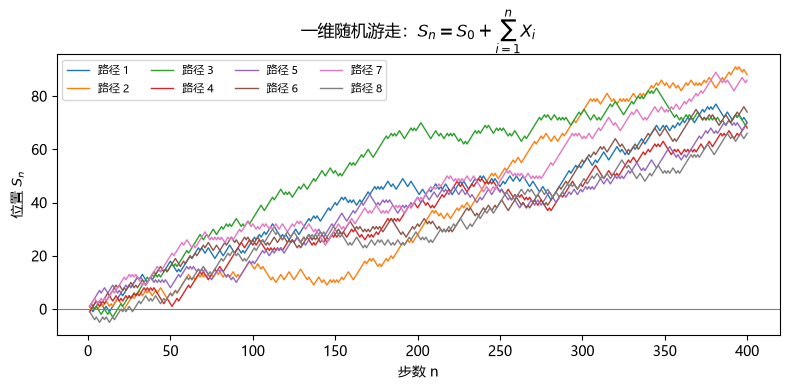

In [15]:
# 图中文字体：DejaVu Sans 没有汉字
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei"]
plt.rcParams["axes.unicode_minus"] = False

# 一维随机游走：P(X_i = 1) = p，P(X_i = -1) = 1 - p
# S_n = S_0 + sum_{i=1}^{n} X_i
p = 0.6
n = 400
S0 = 0
n_paths = 8

np.random.seed(42)
fig, ax = plt.subplots(figsize=(8, 4))
for i in range(n_paths):
    X = np.random.choice([1, -1], size=n, p=[p, 1 - p])
    S = S0 + np.cumsum(X)
    ax.plot(range(1, n + 1), S, linewidth=1, label=f"路径 {i + 1}")

ax.axhline(S0, color="gray", linewidth=0.8)
ax.set_title(r"一维随机游走：$S_n = S_0 + \sum_{i=1}^{n} X_i$")
ax.set_xlabel("步数 n")
ax.set_ylabel(r"位置 $S_n$")
ax.legend(ncol=4, fontsize=8)
plt.tight_layout()


<Axes: title={'center': 'Random Walk'}>

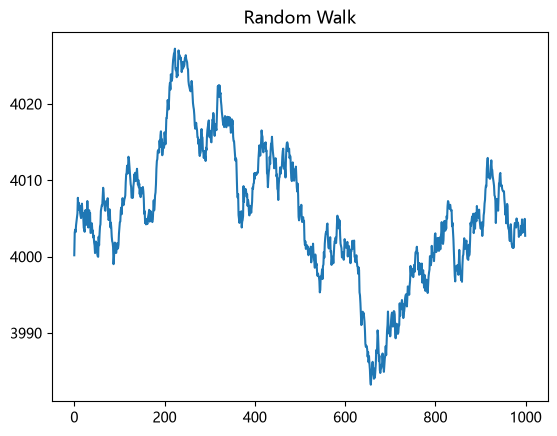

In [ ]:
# 生成一个随机游走的数据，初始值设为4000
data = np.random.randn(1000)
s = pd.Series(data)
random_walk = 4000 + s.cumsum()
random_walk.plot(title="Random Walk")

In [18]:
random_walk.index

RangeIndex(start=0, stop=1000, step=1)

In [ ]:
s.shape

### 为随机游动序列添加时间索引

In [19]:
# 生成500个交易日的日期序列（从当前日期开始）
from datetime import datetime, timedelta
periods=1000
dates = pd.date_range("20261001", periods=periods)
dates

DatetimeIndex(['2026-10-01', '2026-10-02', '2026-10-03', '2026-10-04',
               '2026-10-05', '2026-10-06', '2026-10-07', '2026-10-08',
               '2026-10-09', '2026-10-10',
               ...
               '2029-06-17', '2029-06-18', '2029-06-19', '2029-06-20',
               '2029-06-21', '2029-06-22', '2029-06-23', '2029-06-24',
               '2029-06-25', '2029-06-26'],
              dtype='datetime64[us]', length=1000, freq='D')

<Axes: title={'center': 'Random Walk'}>

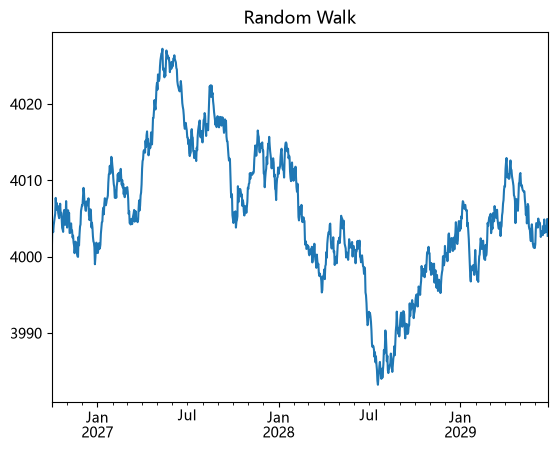

In [20]:
# s的index设置为dates
random_walk.index= dates
random_walk.plot(title="Random Walk")

In [21]:
random_walk

2026-10-01    4000.175211
2026-10-02    4003.160470
2026-10-03    4003.527952
2026-10-04    4003.214422
2026-10-05    4004.136224
                 ...     
2029-06-22    4004.036183
2029-06-23    4003.240626
2029-06-24    4003.665020
2029-06-25    4004.944538
2029-06-26    4002.727720
Freq: D, Length: 1000, dtype: float64

## dataframe

大家打开一个EXCEL数据，感受一下data

In [24]:
a = np.random.randn(500, 4) + 4000
a

array([[4000.98539971, 3998.41415436, 4000.17648418, 4000.45122602],
       [3999.9268927 , 3999.20922908, 4001.01593722, 3999.59662025],
       [3998.51481384, 3997.95052551, 4001.26084952, 4000.61666398],
       ...,
       [3999.59629657, 4000.82914904, 3997.60892143, 3998.98019867],
       [4000.97925974, 3999.75034446, 4000.20754229, 3998.65321434],
       [4001.847867  , 4001.19052964, 3999.79931478, 3999.59530414]],
      shape=(500, 4))

In [25]:
import pandas as pd
import numpy as np

In [ ]:
data = np.random.randn(500, 4)+4000
index = pd.date_range("20260101", periods=500)
columns = list(["close","pre_close","vol","shares"])

In [30]:
## dataframe creation, add data as a parameter
df = pd.DataFrame(data = data, columns = columns,  index = index)
df 

,close,pre_close,vol,shares
2026-01-01,4001.029604,4001.982470,4000.953760,4002.171803
2026-01-02,3999.077649,3999.180613,3998.811059,4000.441761
2026-01-03,4000.175604,3999.848049,4000.809259,4001.232329
2026-01-04,3998.474338,3999.403028,4000.820144,3999.532261
2026-01-05,3999.201794,4001.018537,3998.710500,3999.698420
...,...,...,...,...
2027-05-11,4000.553627,4000.420310,4000.591801,4001.259284
2027-05-12,4001.862869,4000.124663,4001.099464,3999.648340
2027-05-13,4001.185007,4001.061509,4001.008416,4000.094070
2027-05-14,3999.331642,3998.605472,3999.959963,4001.533013


**金融数据处理与pandas:**
- 在金融数据中时间标签非常重要；
- 后续做数据预处理和数据存取可以经常使用pandas工具。

# 数据
## Data-centric AI

https://www.datacentricai.org/

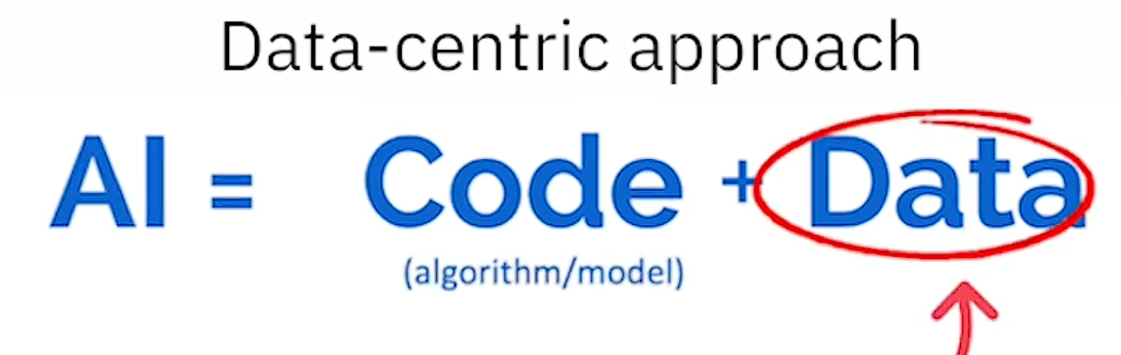

https://scale.com/


We provide high-quality data and full-stack technologies that power the world’s leading models and enable enterprises and governments to build, deploy, and oversee AI applications that deliver real impact. 


## 大模型的上下文工程（Context Engineering）

https://code-b.dev/blog/context-engineering

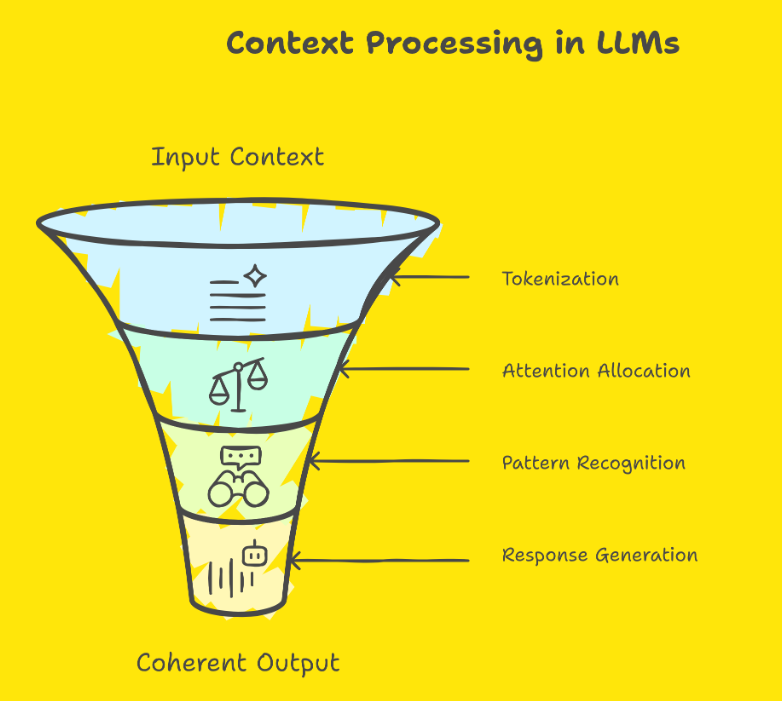

## 金融领域的数据
<img src="../../pic/量化交易黑箱.png" align='left' height="300" width="600"/>

阿尔法（α）：指扣除市场基准回报率后的投资回报率

## 数据分类

- 价格数据：不仅报告资产价格，也包括交易行为相关数据，例如交易量 （一般是结构化的数值型数据）
- 基本面数据：企业相关财务数据、国家或行业宏观数据、新闻公告与重大事件、行业分析、交易数据
- ......

我们可以参考：CSMAR和Tushare官网查看更多数据分类


数据质量

- “垃圾进、垃圾出”:数据时间长度、数据差错
- 注意价格数据的复权：以前复权为例（某支股票10元/股，因除权(例如配股）等原因变为了5元/股，并且除此之外，当天股价没有其他涨跌幅的变化，那进行前复权以后，K线图显示的就是，当天与前一天的股价都是5元，之前的股价也都一律按比例缩小，变为一条连续的曲线）

[股票除权](https://baike.baidu.com/item/%E8%82%A1%E7%A5%A8%E9%99%A4%E6%9D%83/9109013?fr=aladdin)

## 数据来源

- 交易所：价格数据
- 政府：宏观经济数据，例如，失业率、通货膨胀率、GDP
- 企业：财务报告及其他公告
- 新闻机构
- 第三方数据供应商：CSMAR、RESSET数据库、tushare、akshare

**如何选择数据源**
- 数据质量（资金允许的情况下，下载多方数据）
- 成本（金额、时间，个别数据提供商提供下载速度较慢）
- 便捷性（有的直接下载，有的需要简单API调用）

# 第三方数据库（学校图书馆购买的数据库）

## CSMAR
https://cn.gtadata.com/

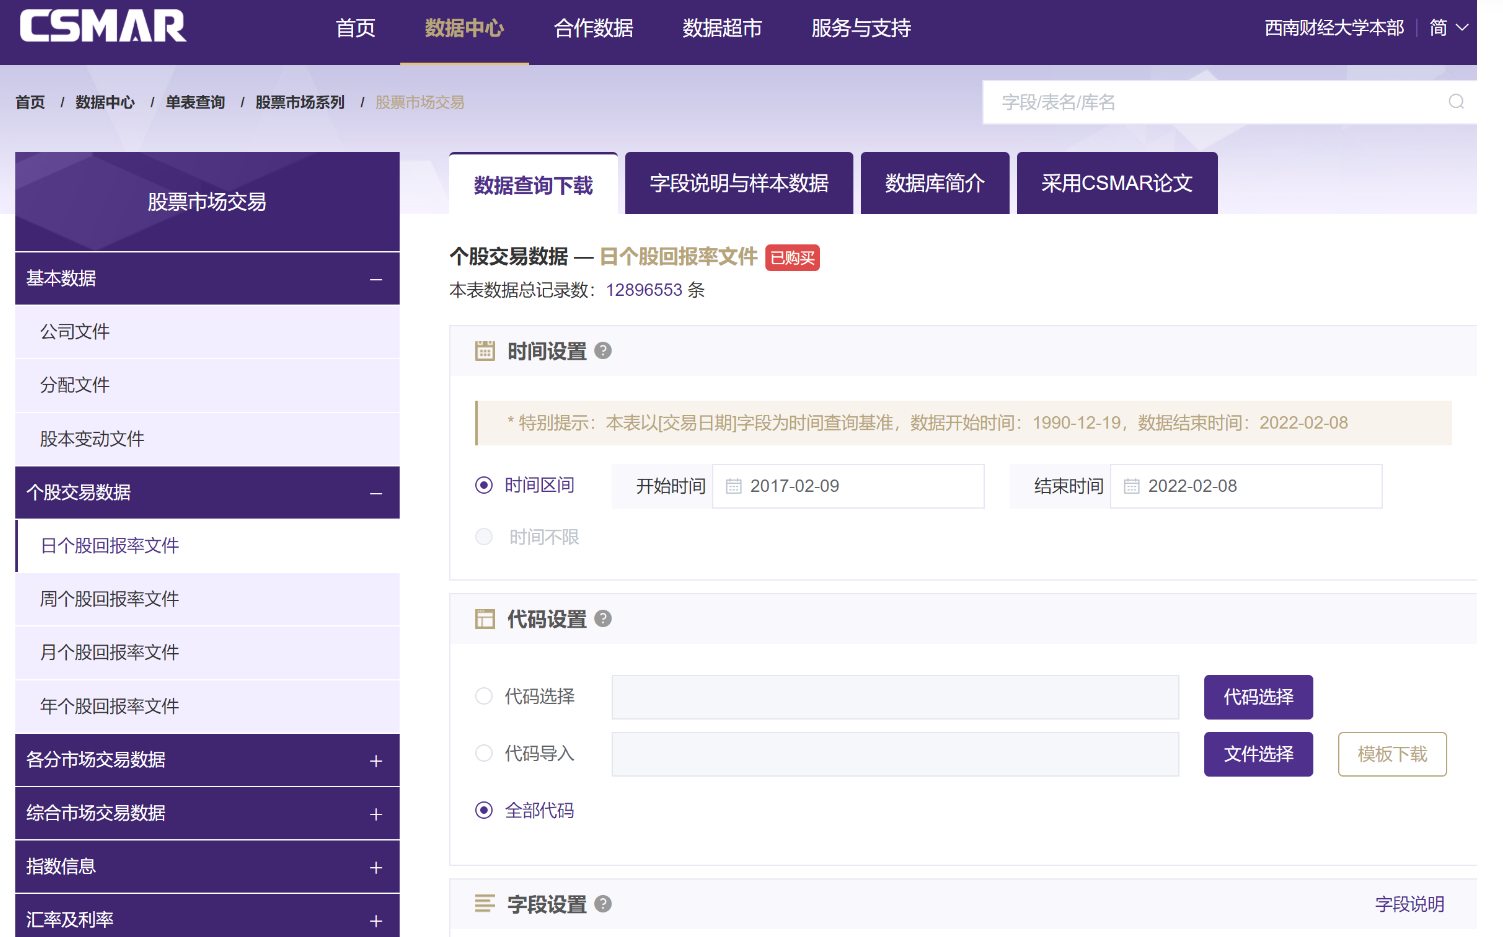

## RESSET

RESSET数据库：数据库历史数据完整、涵盖广泛，包括股票、债券、基金、研究报告、融资融券、宏观统计、行业统计、金融统计、外汇、期货、黄金等十三大模块，并且研发团队与国内外著名高校合作计算了丰富的衍生指标。充分参照国际著名数据库的设计标准，又结合中国金融市场的实际情况，以实证研究为导向整体设计而成。为模型检验、投资研究、实证研究、学科与实验室建设等提供专业服务的数据平台。

RESSET沪港通数据库：涵盖了沪股通和港股通的成分构成情况、沪港通十大成交活跃股票信息、港股通交易的参考汇率及结算汇率、沪港通交易的每日额度信息、各类交易的合资格股票名单等数据，包含61个变量，1万9千多条数据，数据内容全面、丰富。

RESSET高频数据库（分时）：提供自1999年以来的沪深交易所1分钟、5分钟、10分钟、15分钟、20分钟、30分钟、40分钟、60分钟等间隔的分时高频数据。按照分时区间进行归类，提供多种下载格式。

# 使用tushare获取行情数据

**我提前下载了一些数据，方便大家使用**
- 股票列表：data/cn_stock/stock_list.csv
- 指数列表：data/cn_stock/index_list.csv
- 上证指数行情数据：data/cn_stock/index_sh.csv
- 地产指数行情数据：data/cn_stock/house_index.csv
- cctv新闻数据：data/cctv_news/cctv_news.csv



- 如果大家的基础积分下载数据有每分钟次数限制，可以考虑通过**并发和次数控制**，这样可以提升效率。

## 安装并使用tushare
- 注册用户
- 通过如下两种方式可以获得数据
1. 通过tushare python包
2. 使用http协议直接获取

[tushare](https://www.tushare.pro/)


pip install tushare --upgrade

## 获取并管理自己的Token

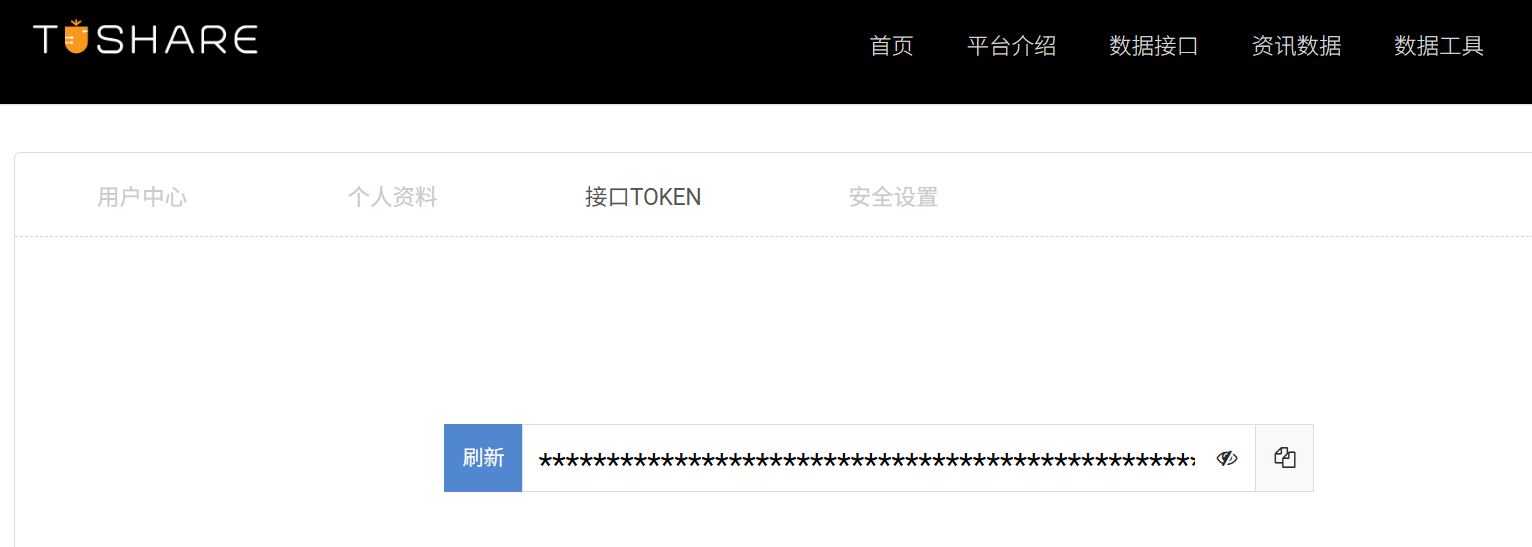

**敏感隐私信息大家不要直接硬编码到代码中**
- 例如tushare token

In [1]:
import tushare as ts

In [1]:
from dotenv import load_dotenv
import os
import tushare as ts

load_dotenv()                       # 读取根目录 .env
ts.set_token(os.getenv('TUSHARE_TOKEN'))
os.getenv('TUSHARE_TOKEN')
# pro = ts.pro_api()                   # 之后即可调数据接口

'5c426f5af978fd42fe0f81fe7e60c02ada33d6c79347b61ccb44f521'

### 最合理的做法
- 放到.env文件

工作步骤
- 第一步：新建一个.env文件，并将敏感信息写入到文件中


TUSHARE_TOKEN = "your token"

- 第二步：应用load_dotenv()读取并设置环境变量

In [ ]:
# 使用dotenv库加载环境变量
from dotenv import load_dotenv
load_dotenv()

# 获取token
import os

In [ ]:
# 遍历所有环境变量
# for key, value in os.environ.items():
#     print(f'{key}: {value}')

In [ ]:
token = os.environ.get("TUSHARE_TOKEN")

In [ ]:
token

1.dotenv库的作用 ： 

- load_dotenv() 函数的主要功能是从项目目录下的 .env 文件中读取键值对，并将其 临时设置 为当前Python进程的环境变量，而不是修改系统级别的环境变量。

2.作用范围限制 ：
- 仅影响当前运行的Python进程及其子进程
- 不会修改Windows系统的全局环境变量
- 当Python程序结束时，通过 load_dotenv() 设置的环境变量也会随之消失

3.实际应用场景 ：
- 用于在开发环境中安全地管理敏感信息（如API密钥、数据库连接字符串等）
- 允许不同环境（开发、测试、生产）使用不同的配置，而无需修改代码

### 不合理的做法(为了便捷，课程教学中也偶尔这么做)

In [2]:
import tushare as ts

# 下面这个token本学期大家可以使用，如果同时使用，可能会出现调研频次限制（积分在2000左右）
token = "5c426f5af978fd42fe0f81fe7e60c02ada33d6c79347b61ccb44f521"

ts.set_token(token=token)

pro = ts.pro_api()

In [ ]:
# 通过 stock_basic 接口获取中国上市公司的股票列表
# 接口文档：https://www.tushare.pro/document/2?doc_id=25
# exchange 留空 = 全部交易所（SSE上交所 / SZSE深交所 / BSE北交所）
# list_status: L上市 / D退市 / P暂停上市
stock_basic = pro.stock_basic(
    list_status='L',
    fields='ts_code,symbol,name,area,industry,list_date,list_status,delist_date,exchange,market'
)
stock_basic

## 获取公司列表
- 要学会使用tushare的接口文档

[基础信息](https://www.tushare.pro/document/2?doc_id=25)

交易所 
- SSE上交所 
- SZSE深交所 
- BSE北交所

In [3]:
# 下面代码只获取所有的股票
stock_basic = pro.stock_basic(fields='ts_code,symbol,name,area,industry,list_date,list_status,delist_date,exchange,market')

In [4]:
stock_basic

,ts_code,symbol,name,area,industry,list_date,list_status,delist_date,exchange,market
0,920202.BJ,920202,安达股份,浙江,汽车配件,20260929,L,None,BSE,北交所
1,920025.BJ,920025,凯达重工,江苏,专用机械,20260923,L,None,BSE,北交所
2,001246.SZ,001246,力勤资源,浙江,小金属,20260930,L,None,SZSE,主板
3,920229.BJ,920229,世纪数码,河南,纺织机械,20260922,L,None,BSE,北交所
4,301716.SZ,301716,鸿富诚,深圳,半导体,20260929,L,None,SZSE,创业板
...,...,...,...,...,...,...,...,...,...,...
5567,000008.SZ,000008,神州高铁,北京,运输设备,19920507,L,None,SZSE,主板
5568,000007.SZ,000007,全新好,深圳,其他商业,19920413,L,None,SZSE,主板
5569,000006.SZ,000006,深振业A,深圳,区域地产,19920427,L,None,SZSE,主板
5570,000002.SZ,000002,万科A,深圳,全国地产,19910129,L,None,SZSE,主板


In [ ]:
# 下面代码只获取所有的退市股票
stock_basic_D = pro.stock_basic(list_status = "D", fields='ts_code,symbol,name,area,industry,list_date,list_status,delist_date,exchange,market')

In [ ]:
stock_basic_D

大家可以保存数据：
- 例如使用to_csv保存到stock_list.csv

In [ ]:
stock_basic.to_csv('stock_list.csv', index=False, encoding='utf-8-sig')

## 获取公司基本情况

https://www.tushare.pro/document/2?doc_id=112

In [ ]:
stock_company = pro.stock_company(exchange='SSE', fields='ts_code,chairman,manager,secretary,reg_capital,setup_date,province')

In [ ]:
stock_company.head()

## 获取股票每日行情

### 获取未复权行情

分红、送股、拆股、配股等行为都会导致股价的异常变动，但资产的实际价值并未发生变化。股价的剧烈变动会影响很多我们经常使用的财务指标或量价指标。

[量化投资中如何最准确的计算股票前后复权价](https://zhuanlan.zhihu.com/p/283168542)

下面使用daily获取的是未复权行情

获取一只股票平安银行的日线行情数据
stock_ts_code = '000001.SZ'

In [5]:
import pandas as pd
ts_code = "000001.sz"
# get the daily trading data of 000001.sz
df = pro.daily(ts_code= ts_code, start_date='20250820', end_date='20261031')

In [6]:
df

,ts_code,trade_date,open,high,low,close,pre_close,change,pct_chg,vol,amount
0,000001.SZ,20260929,11.30,11.41,11.28,11.35,11.30,0.05,0.4425,690979.09,7.846328e+05
1,000001.SZ,20260928,11.28,11.41,11.27,11.30,11.30,0.00,0.0000,715341.43,8.105758e+05
2,000001.SZ,20260924,11.35,11.47,11.29,11.30,11.35,-0.05,-0.4405,1043818.72,1.186737e+06
3,000001.SZ,20260923,11.68,11.71,11.55,11.60,11.71,-0.11,-0.9394,906725.65,1.052015e+06
4,000001.SZ,20260922,11.70,11.75,11.62,11.71,11.73,-0.02,-0.1705,759457.32,8.877031e+05
...,...,...,...,...,...,...,...,...,...,...,...
265,000001.SZ,20250826,12.45,12.50,12.30,12.36,12.45,-0.09,-0.7229,1383598.61,1.709561e+06
266,000001.SZ,20250825,12.12,12.53,12.10,12.45,12.06,0.39,3.2338,3045087.53,3.761289e+06
267,000001.SZ,20250822,12.15,12.17,11.98,12.06,12.15,-0.09,-0.7407,1644259.77,1.979461e+06
268,000001.SZ,20250821,12.05,12.19,12.03,12.15,12.07,0.08,0.6628,1217418.25,1.477053e+06


### 对数据做初步预处理（选做）
- set trade_date as datetime type：pd.to_datetime

- set trade_date as index： df.set_index('trade_date', inplace=True)

- sort df according to index： df.sort_index()

In [ ]:
# set trade_date as datetime type - pd.to_datetime(df.trade_date)
df.trade_date = 

In [ ]:
df

In [ ]:
# set trade_date as index - df.set_index(["trade_date"])
df.set_index(["trade_date"], inplace=True)

In [ ]:
# sort df according to index  - df.sort_index(ascending= False)


### 尝试理解市场交易数据

- pre_close today may be not equal to the close price of the last day?

- check how the pct_chg is computed? - delta / df["pre_close"] * 100

- can pct_chg be zero?
 

In [ ]:
# check how the pct_chg is computed



### 获取复权行情


#### 第一步：理解除权前的情况
- **除权前日**：这家股票的流通盘是5000万股，每股价格10元。当天的成交量是500万股，换手率是10%（因为500万股 ÷ 5000万股 = 10%）。换手率表示股票的交易活跃度。

#### 第二步：什么是“10送10”除权？
- **10送10**：意思是每持有10股股票，就免费送你10股。这相当于你的股票数量翻倍了。比如，你原来有1000股，送股后变成2000股。
- **除权效应**：送股后，流通盘从5000万股变成1亿股（翻倍）。但公司的总价值没变，所以股价需要调整。除权报价的计算是：原价10元 ÷ 2 = 5元。所以，除权当天的开盘参考价是5元。

#### 第三步：除权当天的“填权行情”
- **除权当日**：股票价格从5元上涨到5.5元，涨幅10%（因为（5.5-5）÷5 = 10%）。这被称为“填权行情”，意思是股价在除权后上涨，部分抵消了除权带来的价格下降。
- **成交量变化**：当天的成交量是1000万股。由于流通盘现在变成1亿股，换手率仍然是10%（1000万股 ÷ 1亿股 = 10%）。所以，换手率和除权前日一样，表示交易活跃度相当。

#### 第四步：为什么需要“复权处理”？
- **问题**：如果不处理，股价走势图会突然从10元跳到5元，看起来像暴跌，但实际上是因为送股导致的。成交量也从500万股跳到1000万股，但股本变了，直接比较会误导人。
- **复权的目的**：复权就是为了消除除权的影响，让股价和成交量在前后时间点可比，真实反映涨跌。

#### 第五步：如何计算复权价格和复权成交量？
- **复权价格**：除权后股价是5.5元，但由于送了股，每股实际对应除权前的2股。所以，复权价格 = 5.5元 × 2 = 11元。这样，与除权前日的10元相比，上涨了10%（（11-10）÷10 = 10%），真实反映了股价上涨。
- **复权成交量**：除权当日成交量是1000万股，但这是基于新股本1亿股。为了与除权前日的500万股成交量可比，需要调整回除权前的股本基础。由于股本翻倍，复权成交量 = 1000万股 ÷ 2 = 500万股。这样，成交量在除权前后都是500万股，换手率都是10%，具有可比性。

#### 简单总结
- **除权**：就像把一张10元的钞票换成两张5元的钞票，总价值不变，但数量翻倍。
- **填权**：换完后，5元的钞票涨到5.5元，相当于总价值增加了。
- **复权**：在图表上，把5.5元“还原”成11元，这样就能直接看出从10元涨到11元，上涨10%。成交量也“还原”回原来的基础，方便比较。

- 前复权

前复权（Forward Adjustment）是以最新一个交易日的真实股价为基准，反向调整 “除权除息日之前” 的所有历史股价和成交量，让 K 线图从历史延续到当前时，当前股价与市场真实报价完全一致。

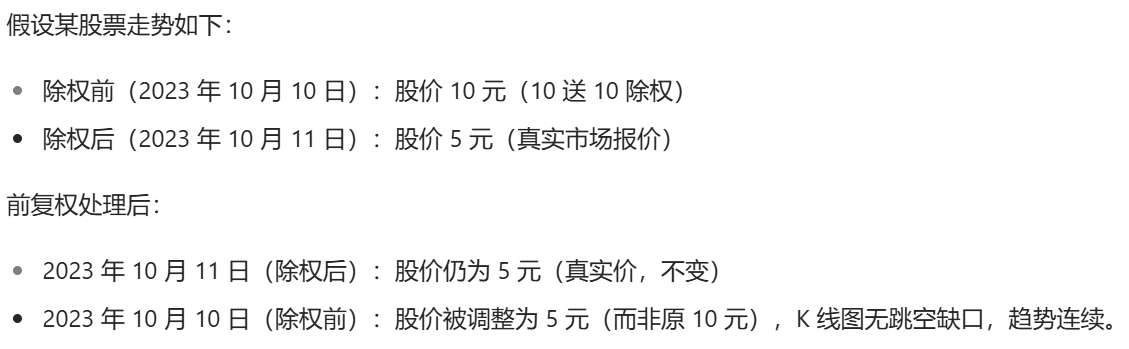

- 后复权
后复权（Backward Adjustment）是以 “除权除息日之前的某一历史股价” 为基准，正向调整 “除权除息日之后” 的所有股价和成交量，让 K 线图从当前回溯到历史时，历史股价与当时的真实报价完全一致。

In [ ]:
ts.set_token(token)

In [8]:
#取000001的前复权行情
ts_code = "000001.SZ"

fuquan = ts.pro_bar(ts_code=ts_code, adj='qfq', start_date='20250820', end_date='20261031')
fuquan

,ts_code,trade_date,open,high,low,close,pre_close,change,pct_chg,vol,amount
0,000001.SZ,20260929,11.30,11.41,11.28,11.35,11.30,0.05,0.44,690979.09,7.846328e+05
1,000001.SZ,20260928,11.28,11.41,11.27,11.30,11.30,0.00,0.00,715341.43,8.105758e+05
2,000001.SZ,20260924,11.35,11.47,11.29,11.30,11.35,-0.05,-0.44,1043818.72,1.186737e+06
3,000001.SZ,20260923,11.43,11.46,11.30,11.35,11.46,-0.11,-0.96,906725.65,1.052015e+06
4,000001.SZ,20260922,11.45,11.50,11.37,11.46,11.48,-0.02,-0.17,759457.32,8.877031e+05
...,...,...,...,...,...,...,...,...,...,...,...
265,000001.SZ,20250826,11.55,11.60,11.41,11.47,11.55,-0.08,-0.69,1383598.61,1.709561e+06
266,000001.SZ,20250825,11.24,11.62,11.22,11.55,11.19,0.36,3.22,3045087.53,3.761289e+06
267,000001.SZ,20250822,11.27,11.29,11.11,11.19,11.27,-0.08,-0.71,1644259.77,1.979461e+06
268,000001.SZ,20250821,11.18,11.31,11.16,11.27,11.20,0.07,0.63,1217418.25,1.477053e+06


In [ ]:
fuquan.shape

In [ ]:
# set trade_date as datetime type
fuquan['trade_date'] = pd.to_datetime(fuquan['trade_date'])
# set trade_date as index
fuquan.set_index('trade_date', inplace=True)
# sort df according to index
fuquan.sort_index(inplace=True)
fuquan

思考问题： 

- what is the difference between pre_close and close?
- can we use close price directly now?
- should we use qfq or hfq? - 算收益率、做回测时用后复权。


In [ ]:
#取000001的前复权行情
# ts_code = '600519.SH' # 贵州茅台
# ts_code = "688256.SH" # 寒武纪
# ts_code = "688981.SH" # 中心国际
ts_code = "688041.SH" # 海光信息

fuquan = ts.pro_bar(ts_code=ts_code, adj='qfq', start_date='20000101', end_date='20261009')
fuquan.to_csv('688041.csv', index=False)


# 多线程并发

如何加速数据下载？

## 场景：要取10只股票的数据(包裹)


#### 1. 单线程模式（低效版）
1个快递员 → 取第1只股票数据 → 取第2只股票数据 → ... → 取第10只股票数据 → 总耗时100分钟


#### 2. 咱们代码的多线程模式（高效版）
1. 调度员打开5个工作窗口（对应代码中`max_workers=5`）  
2. → 5个快递员同时出发，各自执行任务：  
   - 快递员1 → 取股票A数据  
   - 快递员2 → 取股票B数据  
   - 快递员3 → 取股票C数据  
   - 快递员4 → 取股票D数据  
   - 快递员5 → 取股票E数据  
3. → 谁先完成任务就先回收结果（例如：快递员3先返回，将股票C数据存入`all_data`列表）  
4. → 剩余5只股票（F/G/H/I/J）：待任意快递员空闲后，立即分配新任务（例如：快递员3取完C后，接着取股票F数据）  
5. → 10只股票数据全部获取完成后，计算总耗时（示例：仅需30分钟，效率远高于单线程）

## 多线程并发实现

<img src="../../pic/多线程调度.svg" width="800"/>

### Python中的多线程

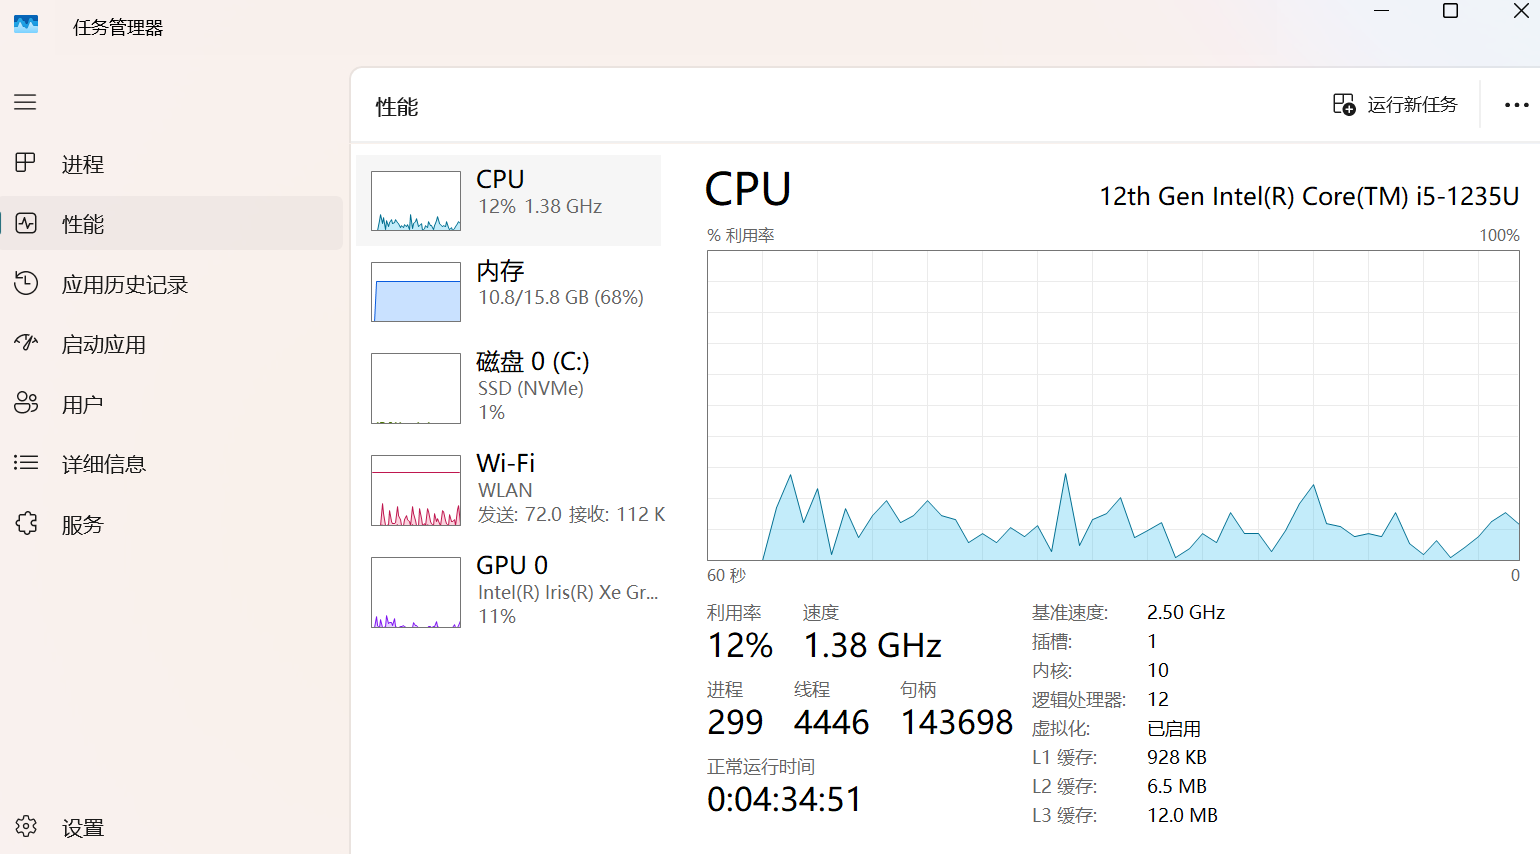

GIL（Global Interpreter Lock，全局解释器锁）不是 Python 语言的特性，而是 CPython 解释器（Python 最主流的官方实现） 的设计限制 —— 它确保：在一个 Python 进程中，同一时间只有一个线程能执行 Python 字节码。

为什么 CPython 要设计 GIL？核心是为了简化「多线程访问 Python 内部共享资源」的安全问题（比如垃圾回收器 GC 要处理内存引用计数）。如果没有 GIL，多线程同时修改共享资源会导致数据混乱，需要更复杂的线程同步机制，反而会降低单线程性能（而 CPython 最初更侧重单线程效率）。

**GIL 下多线程的 “适用边界”**

| 维度                | CPU 密集型任务                          | I/O 密集型任务                          |
|---------------------|-----------------------------------------|-----------------------------------------|
| 核心耗时点          | CPU 持续计算（无空闲）                  | 等待外部资源（CPU 大量空闲）            |
| GIL 行为            | 线程轮流抢 GIL，仅 1 核工作             | 线程 I/O 时释放 GIL，多线程复用 CPU     |
| 多线程效果          | 无法利用多核，切换有额外开销（可能更慢）| 等待时间重叠，CPU 利用率提升（高效）    |
| 推荐方案            | 多进程（绕开 GIL，利用多核）            | 多线程（轻量，低切换开销）       |

多线程（Threading）
- 基于操作系统线程：每个线程由操作系统调度，同一进程内的线程共享内存。
- 抢占式并发：线程的切换由操作系统控制，可能在任意时刻发生（如时间片用完或 I/O 阻塞）。
- 同步阻塞：线程在等待 I/O 时会被阻塞，让出 CPU 资源，但其他线程仍可执行。

### 通过多线程观察 GIL 对 CPU 密集型任务的限制

```
单核CPU核心 (被GIL限制)
  |
  |-- T1 执行计算 (获得GIL) --|
  |                          | (GIL释放点到达，操作系统强制切换)
  |                          v
  |-- T2 执行计算 (获得GIL) --|
  |                          | (GIL释放点到达，操作系统强制切换)
  |                          v
  |-- T1 执行计算 (获得GIL) --| ... 循环往复
  |
  |
多核CPU (核心2, 3, 4)
  |
  |-- (空闲) --|-- (空闲) --|-- (空闲) --| ... 始终空闲
```

In [ ]:
import threading
import time

# 一个CPU密集型函数
def cpu_bound_task(n):
    a, b = 0, 1
    for _ in range(n):
        a, b = b, a + b
    return a

# 定义线程要执行的函数
def worker():
    # 执行一个耗时的计算
    cpu_bound_task(500000)

# --- 单线程执行 ---
print("--- 开始单线程测试 ---")
start_time_single = time.time()
worker()
worker() # 连续执行两次
end_time_single = time.time()
single_thread_time = end_time_single - start_time_single
print(f"单线程执行两次任务，总耗时: {single_thread_time:.2f} 秒\n")

# --- 多线程执行 ---
print("--- 开始多线程测试 ---")
start_time_multi = time.time()
# 创建两个线程
t1 = threading.Thread(target=worker)
t2 = threading.Thread(target=worker)

# 启动线程
t1.start()
t2.start()

# 等待所有线程执行完毕
t1.join()
t2.join()

end_time_multi = time.time()
multi_thread_time = end_time_multi - start_time_multi
print(f"双线程执行两个任务，总耗时: {multi_thread_time:.2f} 秒")

# 比较结果
print(f"\n多线程耗时 / 单线程耗时 = {multi_thread_time / single_thread_time:.2f}")

### 定义「模拟网络传输耗时任务」函数

In [ ]:
import time
import concurrent.futures

# 模拟IO密集型任务（如调用接口、读取数据）
def simulate_task(task_id):
    """
    task_id: 任务编号（区分不同任务）
    返回：任务结果字符串
    """
    print(f"任务{task_id} | 开始执行（当前时间：{time.strftime('%H:%M:%S')}）")
    time.sleep(2)  # 核心：模拟2秒耗时（如等待接口返回数据）
    print(f"任务{task_id} | 执行完毕（当前时间：{time.strftime('%H:%M:%S')}）")
    return f"任务{task_id}的结果"

#### 不使用多线程（单线程串行执行）

In [ ]:
# 1. 准备任务列表（5个任务，和多线程保持一致）
task_list = [1, 2, 3, 4, 5]

# 2. 记录开始时间
start_time = time.time()

# 3. 单线程：逐个执行任务（前一个完成，才开始下一个）
single_thread_results = []
for tid in task_list:
    result = simulate_task(tid)
    single_thread_results.append(result)

# 4. 计算总耗时
total_time = time.time() - start_time

# 5. 输出结果
print(f"\n=== 单线程执行完成 ===")
print(f"总耗时：{total_time:.2f} 秒")
print(f"所有任务结果：{single_thread_results}")

#### 使用多线程（ThreadPoolExecutor 并发执行）

**用两个线程示例**


```
CPU核心
  |
  |-- T1: 发起网络请求 (获得GIL) --| (发起请求后，进入I/O等待，主动释放GIL)
  |                                v
  |-- T2: 发起网络请求 (获得GIL) --| (发起请求后，进入I/O等待，主动释放GIL)
  |                                v
  |-- (CPU空闲，等待I/O响应)      | (T1的网络响应返回)
  |                               v
  |-- T1: 处理响应数据 (获得GIL) --| (T1任务完成，释放GIL)
  |                               v
  |-- (CPU空闲)                   | (T2的网络响应返回)
  |                               v
  |-- T2: 处理响应数据 (获得GIL) --| (T2任务完成，释放GIL)
  v

网络/I/O
  |
  |<-- T1 请求发出 -->|-- (等待服务器响应) --|--> T1 响应返回 --|
  |
  |<-- T2 请求发出 -->|-- (等待服务器响应) --|--> T2 响应返回 --|
```

In [ ]:
# 1. 同样的任务列表（保证和单线程公平对比）
task_list = [1, 2, 3, 4, 5]

# 2. 记录开始时间
start_time = time.time()

# 3. 多线程：创建线程池（最多同时运行3个线程，可调整）
multi_thread_results = []
with concurrent.futures.ThreadPoolExecutor(max_workers=3) as executor:
    # 提交所有任务到线程池，返回「未来结果对象」列表
    futures = [executor.submit(simulate_task, tid) for tid in task_list]
    
    # 按「任务完成顺序」获取结果（而非提交顺序）
    for future in concurrent.futures.as_completed(futures):
        result = future.result()  # 取出任务结果
        multi_thread_results.append(result)

# 4. 计算总耗时
total_time = time.time() - start_time

# 5. 输出结果
print(f"\n=== 多线程执行完成 ===")
print(f"总耗时：{total_time:.2f} 秒")
print(f"所有任务结果：{multi_thread_results}")

## 多线程并发获取所有股票的日线行情数据

In [ ]:
# 读取csv数据
import pandas as pd
data_path = "stock_list.csv"
stock_list = pd.read_csv(data_path)
stock_ts_code_list = stock_list['ts_code'].tolist()[:20]
len(stock_ts_code_list)

In [ ]:
stock_list.head()

In [ ]:
# 循环获取所有股票的日线行情数据，ts.pro_bar，获取日期20000101到20250901
# 先生成一个空的DataFrame
#  然后循环获取每个股票的日线行情数据，将数据添加到空的DataFrame中
# 并将最终的DataFrame保存到CSV文件中，文件地址：data/cn_stock/stock_pro_bar.csv

stock_daily_pro_bar = pd.DataFrame()

start_date = '20260101'
end_date = '20261001'

import time
start_time = time.time()
for stock_ts_code in stock_ts_code_list:
    print(stock_ts_code)
    stock_daily = ts.pro_bar(ts_code=stock_ts_code, adj='qfq', start_date=start_date, end_date=end_date)
    stock_daily_pro_bar = pd.concat([stock_daily_pro_bar, stock_daily], ignore_index=True)
    print(f'已获取{stock_ts_code}的日线行情数据')
end_time = time.time()
print(f'获取所有股票数据耗时: {end_time - start_time} 秒')

In [ ]:
import pandas as pd

# 当股票数据获取函数
def fetch_single_stock_data(ts_code):
    """获取单只股票数据 - 详细错误信息版本"""
    try:
        print(f"正在获取 {ts_code} 的数据...")
        # 使用正确的接口名：pro_bar
        data = ts.pro_bar(ts_code=stock_ts_code, adj='qfq', start_date=start_date, end_date=end_date)       
        # print(f"{ts_code}: 成功获取 {len(data)} 条记录")
        return data
    except:
        return pd.DataFrame()

In [ ]:
# 调试单个股票
test_code = '000001.SZ'
single_test = fetch_single_stock_data(test_code)

In [ ]:
single_test.head()

In [ ]:
import concurrent
import time
start_time = time.time()
# 获取数据
all_data = []
with concurrent.futures.ThreadPoolExecutor(max_workers=5) as executor:
    futures = [executor.submit(fetch_single_stock_data, code) for code in stock_ts_code_list]
    
    for future in concurrent.futures.as_completed(futures):
        result = future.result()
        if result is not None:
            all_data.append(result)
            print(f"已获取 {len(all_data)} 只股票数据")
end_time = time.time()
print(f"获取所有股票数据耗时: {end_time - start_time} 秒")


In [ ]:
len(all_data)

In [ ]:
all_data[2]

In [ ]:
# # 合并和保存
# if all_data:
#     final_df = pd.concat(all_data, ignore_index=True)
#     final_df.to_csv('../data/cn_stock/stock_pro_bar.csv', index=False, encoding='utf-8-sig')
# else:
#     print("未获取到任何数据")

In [ ]:
# final_df.head()

执行顺序：

1. **建池。** 进入 `with` 时，主线程建立一个线程池，最多 5 个工作线程。此时还没有开始拉数据。
2. **交任务。** `executor.submit(...)` 把「拉取这只股票」放进队列，并立刻返回一张回执 `Future`，不会等这只股票拉完。这一行结束时，全部股票都已入队，`futures` 的个数与股票数相同。
3. **并行等待。** 池子最多让 5 个线程同时调用 `ts.pro_bar` 并等待返回。有线程完成，就立刻接手队列里的下一只，不必等这一批 5 个一起结束。
4. **按完成顺序收结果。** `as_completed` 谁先返回，就先给出谁的 `Future`，与 `stock_ts_code_list` 的顺序无关。主线程用 `future.result()` 取出 DataFrame；函数里的异常也会在这里抛出。
5. **关池。** 离开 `with` 前，已提交的任务会全部做完，然后关闭线程池。因此后面的 `end_time` 是全部股票都回来的时刻。

<img src="../../pic/多线程调度.svg" width="800"/>